# Evaluating Natural Language Explanations of Food Recommendation System XFoodRec Across Several LLMs

Authors: Junxuan Ling, Tianyi Liu, Anqi Zhou

# 0. Document Instructions

## 0.1. Git Version Control

After making modifications, please use Colab's function of "Save in Github to keep changes" (Github authorization required) to commit the changes to the repository (Your own branch if needed).

**NOTE**: When A modifies this notebook, but have not commited to Github, if B opens this notebook, they will see the Github old version.

## 0.2. Handle persistent data storage

Mount Google Drive instead of relying on Colab's temporary run-time storage.

**IMPORTANT:** Although Google Colab allows collaboration of the notebook, data and folders are originally in Junxuan's drive, this could cause issues when refering to the mounted directory path. To allow the code to work for all of us, (who's not junxuan) please create a **short-cut** of Junxuan's shared folder in our own Google Drive, path `MyDrive/`.

In [1]:
# load from drive
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 0.3 Setup and data loading

Run the notebook from top to bottom. It does not parse the explanations again; it reads what Step 2 saved in 2.1e.

| File | Saved by | Used for |
|---|---|---|
| `explanation_lemmas.parquet` | Step 1 (preprocessing) | The 536 explanations with their persona, recipe and rank |
| `explanation_docs.spacy` | Step 2 (2.1e) | The parsed explanations, with each word's base form and whether it belongs to the recipe title |
| `user_factor_mentions.parquet` | Step 2 (2.1e) | Where each explanation names its persona's own values |

**Shared files:** everything in `processed/` is shared by the whole team. Rerunning the 2.1e cells of Step 2 overwrites these files for everyone. If a rule in Step 2 (2.0 or 2.1) changes, rerun Step 2 up to 2.1e before this notebook, otherwise this notebook reads the old results. The last cell here saves `transparency_levels.parquet` in the same folder.

In [2]:
%pip install -q spacy pyarrow

In [3]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import spacy
from spacy.tokens import DocBin

project_dir = Path("/content/drive/MyDrive/XFoodRec_Project_Data")
data_dir = project_dir / "raw"
processed_dir = project_dir / "processed"
persona_path = data_dir / "personas.json"

In [4]:
# raw persona profiles and explanations
with (data_dir / "personas.json").open("r", encoding="utf-8") as f:
    personas = json.load(f)

with (data_dir / "recommendations.json").open("r", encoding="utf-8") as f:
    recommendations = json.load(f)

# explanation identifiers from task 1
explanation_index = pd.read_parquet(
    processed_dir / "explanation_lemmas.parquet"
)[["recommendation_id", "persona_id", "recipe_id", "rank"]]

# explanation-level transparency from task 3
transparency_df = pd.read_parquet(
    processed_dir / "transparency_levels.parquet"
)

# claim-level verification from task 2
verified_claims_df = pd.read_parquet(
    processed_dir / "verified_claims.parquet"
)

assert explanation_index["recommendation_id"].is_unique
assert transparency_df["recommendation_id"].is_unique

assert set(transparency_df["recommendation_id"]) == set(
    explanation_index["recommendation_id"]
), "transparency and explanation ids differ"

assert verified_claims_df["recommendation_id"].isin(
    explanation_index["recommendation_id"]
).all(), "claims contain unknown explanation ids"

print("Personas:", len(personas))
print("Explanations:", len(explanation_index))
print("Transparency records:", len(transparency_df))
print("Verified claims:", len(verified_claims_df))

Personas: 40
Explanations: 536
Transparency records: 536
Verified claims: 1551


# 4. Bias & Fairness Analysis

## 4.1 Investigate persona characteristics

### a. Dietary goal

In [5]:
personas_df = pd.json_normalize(personas).rename(
    columns={"id": "persona_id"}
)

assert personas_df["persona_id"].is_unique, "duplicate persona ids"

# keep the original goal
personas_df["dietary_goal"] = (
    personas_df["profile.dietary_goal"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

goal_summary = (
    personas_df["dietary_goal"]
    .fillna("missing")
    .value_counts()
    .rename_axis("dietary_goal")
    .to_frame("personas")
)

goal_summary["percent"] = (
    100 * goal_summary["personas"] / len(personas_df)
).round(1)

display(goal_summary)
print("\nPersonas:", len(personas_df))
print("Missing dietary goals:", personas_df["dietary_goal"].isna().sum())

,personas,percent
dietary_goal,,
Medical Management,14,35.0
Maintenance,8,20.0
Weight Loss,7,17.5
Energy Boost,6,15.0
Muscle Gain,5,12.5



Personas: 40
Missing dietary goals: 0


### b. Health status

In [6]:
selected_conditions = personas_df[
    "profile.dietaryProfile.healthConditions.selected"
]

personas_df["health_status"] = selected_conditions.map(
    lambda values: ("yes" if len(values) else "no")
    if isinstance(values, (list, np.ndarray))
    else pd.NA
)

health_summary = (
    personas_df["health_status"]
    .fillna("missing")
    .value_counts()
    .rename_axis("health_status")
    .to_frame("personas")
)

health_summary["percent"] = (
    100 * health_summary["personas"] / len(personas_df)
).round(1)

display(health_summary)
print("Missing health status:", personas_df["health_status"].isna().sum())

,personas,percent
health_status,,
yes,30,75.0
no,10,25.0


Missing health status: 0


In [7]:
# health information rather than selected
health_other = personas_df[
    "profile.dietaryProfile.healthConditions.other"
].astype("string").str.strip()

display(
    personas_df.loc[
        health_other.fillna("").ne(""),
        [
            "persona_id",
            "health_status",
            "profile.dietaryProfile.healthConditions.selected",
            "profile.dietaryProfile.healthConditions.other",
        ],
    ]
)

,persona_id,health_status,profile.dietaryProfile.healthConditions.selected,profile.dietaryProfile.healthConditions.other
3,user_04,yes,[Anemia],Iron-deficiency anemia
5,user_06,yes,[Post-Surgery],Post-bariatric surgery
7,user_08,yes,[Kidney Disease],CKD stage 3
9,user_10,yes,[Autism Spectrum],Sensory processing challenges
12,user_13,yes,[PKU],Phenylketonuria
13,user_14,yes,[Food Allergy],Alpha-gal syndrome
17,user_18,yes,[ARFID],Avoidant/Restrictive Food Intake Disorder
20,user_21,yes,[EoE],Eosinophilic esophagitis
33,user_34,yes,[Pancreatitis],Chronic pancreatitis
37,user_38,yes,[Food Allergy],Oral allergy syndrome


### c. Dietary restriction

In [8]:
selected_restrictions = personas_df[
    "profile.dietaryProfile.dietaryRestrictions.selected"
]

personas_df["dietary_restriction"] = selected_restrictions.map(
    lambda values: ("yes" if len(values) else "no")
    if isinstance(values, (list, np.ndarray))
    else pd.NA
)

restriction_summary = (
    personas_df["dietary_restriction"]
    .fillna("missing")
    .value_counts()
    .rename_axis("dietary_restriction")
    .to_frame("personas")
)

restriction_summary["percent"] = (
    100 * restriction_summary["personas"] / len(personas_df)
).round(1)

display(restriction_summary)
print("Missing dietary restriction:", personas_df["dietary_restriction"].isna().sum())

,personas,percent
dietary_restriction,,
yes,32,80.0
no,8,20.0


Missing dietary restriction: 0


In [9]:
# restrictions rather than selected
restriction_other = personas_df[
    "profile.dietaryProfile.dietaryRestrictions.other"
].astype("string").str.strip()

display(
    personas_df.loc[
        restriction_other.fillna("").ne(""),
        [
            "persona_id",
            "dietary_restriction",
            "profile.dietaryProfile.dietaryRestrictions.selected",
            "profile.dietaryProfile.dietaryRestrictions.other",
        ],
    ]
)

,persona_id,dietary_restriction,profile.dietaryProfile.dietaryRestrictions.selected,profile.dietaryProfile.dietaryRestrictions.other
0,user_01,yes,[Vegan],"High-protein, prefers low-soy options"
1,user_02,yes,[Low Carb],Counts carbs precisely; prefers low-GI foods
2,user_03,yes,[Lactose-Free],Very budget-constrained; batch-cooks
3,user_04,yes,[Vegetarian],"Pregnant; prioritizes iron, folate, choline"
4,user_05,yes,[Gluten-Free],Endurance fueling; needs portable snacks
5,user_06,yes,[High Protein],Small meals; avoids high sugar/fat dumping tri...
6,user_07,yes,[Pescatarian],Avoids shellfish; prefers fatty fish
7,user_08,yes,[Keto],Must monitor potassium/phosphorus; moderate pr...
8,user_09,yes,[Low Acid],Avoids trigger foods on shift; prefers easy prep
9,user_10,no,[],Strong texture aversions; prefers predictable ...


### d. Demographics (age, gender)

In [10]:
personas_df["age"] = pd.to_numeric(
    personas_df["profile.age"], errors="coerce"
)

assert personas_df["age"].dropna().between(0, 120).all(), "check age values"

# use the same age groups as in task 3
personas_df["age_group"] = pd.cut(
    personas_df["age"],
    bins=[0, 18, 40, 60, np.inf],
    labels=["under 18", "18-39", "40-59", "60+"],
    right=False
)

age_summary = (
    personas_df["age_group"]
    .value_counts(sort=False)
    .rename_axis("age_group")
    .to_frame("personas")
)

age_summary["percent"] = (
    100 * age_summary["personas"] / len(personas_df)
).round(1)

display(age_summary)
print("\nMissing age:", personas_df["age"].isna().sum())

,personas,percent
age_group,,
under 18,3,7.5
18-39,21,52.5
40-59,12,30.0
60+,4,10.0



Missing age: 0


In [11]:
# gender categories
personas_df["gender"] = (
    personas_df["profile.gender"]
    .astype("string")
    .str.strip()
    .replace("", pd.NA)
)

gender_summary = (
    personas_df["gender"]
    .fillna("missing")
    .value_counts()
    .rename_axis("gender")
    .to_frame("personas")
)

gender_summary["percent"] = (
    100 * gender_summary["personas"] / len(personas_df)
).round(1)

display(gender_summary)

print("\nMissing gender:", personas_df["gender"].isna().sum())

,personas,percent
gender,,
Female,20,50.0
Male,19,47.5
Non-binary,1,2.5



Missing gender: 0


In [12]:
# display personas demographics
display(
    personas_df[
        [
            "persona_id",
            "dietary_goal",
            "health_status",
            "dietary_restriction",
            "age",
            "age_group",
            "gender",
        ]
    ]
)

,persona_id,dietary_goal,health_status,dietary_restriction,age,age_group,gender
0,user_01,Muscle Gain,no,yes,28,18-39,Male
1,user_02,Medical Management,yes,yes,34,18-39,Female
2,user_03,Weight Loss,no,yes,20,18-39,Non-binary
3,user_04,Medical Management,yes,yes,31,18-39,Female
4,user_05,Energy Boost,yes,yes,26,18-39,Male
5,user_06,Medical Management,yes,yes,45,40-59,Female
6,user_07,Maintenance,yes,yes,52,40-59,Male
7,user_08,Medical Management,yes,yes,60,60+,Female
8,user_09,Energy Boost,yes,yes,29,18-39,Female
9,user_10,Maintenance,yes,no,24,18-39,Male


#### e. persona gorup summary

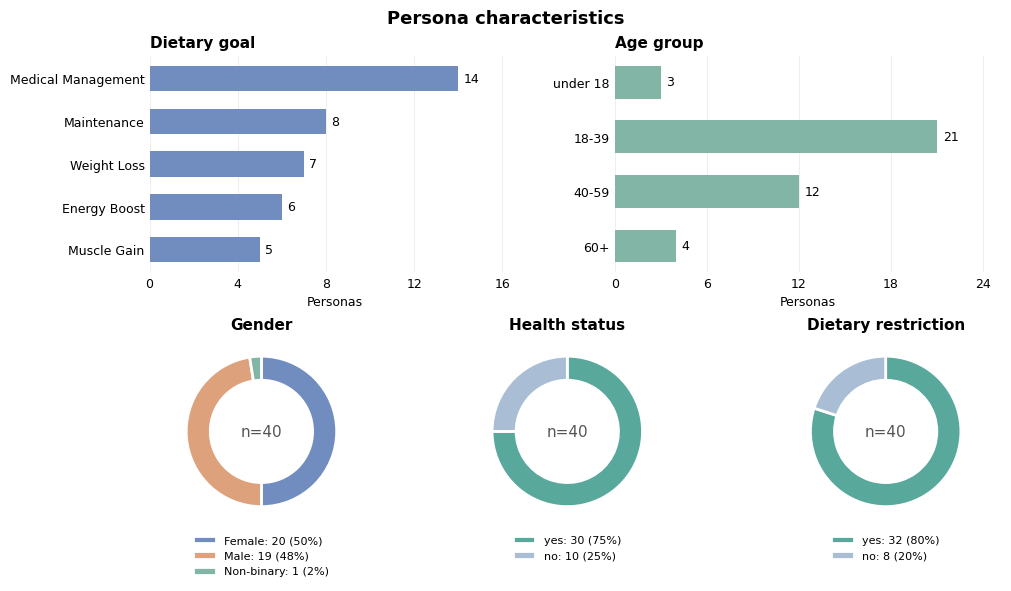

In [13]:
from matplotlib.ticker import MaxNLocator

# compact layout with consistent category colors
colors = {
    "yes": "#59A89C",
    "no": "#A9BED5",
    "missing": "#D9D9D9",
}
palette = ["#718DBF", "#DDA17C", "#83B5A6", "#B69AC5", "#D8C17A"]

fig = plt.figure(figsize=(10, 5.8), layout="constrained")
grid = fig.add_gridspec(2, 6, height_ratios=[1.15, 1])

bar_tables = [
    ("Dietary goal", goal_summary, grid[0, :3]),
    ("Age group", age_summary, grid[0, 3:]),
]

for title, table, position in bar_tables:
    ax = fig.add_subplot(position)
    bars = ax.barh(
        table.index.astype(str),
        table["personas"],
        color="#718DBF" if title == "Dietary goal" else "#83B5A6",
        height=0.6,
    )

    ax.bar_label(bars, padding=4, fontsize=9)
    ax.invert_yaxis()
    ax.set_xlim(0, max(1, table["personas"].max()) * 1.2)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold")
    ax.set_xlabel("Personas", fontsize=9)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=5))
    ax.set_axisbelow(True)
    ax.xaxis.grid(True, color="#EEEEEE")
    ax.tick_params(axis="both", length=0, labelsize=9)
    for spine in ax.spines.values():
        spine.set_visible(False)

donut_tables = [
    ("Gender", gender_summary, grid[1, :2]),
    ("Health status", health_summary, grid[1, 2:4]),
    ("Dietary restriction", restriction_summary, grid[1, 4:]),
]

for title, table, position in donut_tables:
    ax = fig.add_subplot(position)
    counts = table.loc[table["personas"].gt(0), "personas"]
    labels = counts.index.astype(str)

    slice_colors = [
        colors.get(label.lower(), palette[i % len(palette)])
        for i, label in enumerate(labels)
    ]

    wedges, _ = ax.pie(
        counts,
        colors=slice_colors,
        startangle=90,
        counterclock=False,
        wedgeprops={"width": 0.32, "edgecolor": "white", "linewidth": 2},
    )

    ax.text(
        0, 0, f"n={int(counts.sum())}",
        ha="center", va="center", fontsize=11, color="#555555",
    )
    ax.set_title(title, fontsize=11, fontweight="bold")

    ax.legend(
        wedges,
        [
            f"{label}: {count} ({count / counts.sum():.0%})"
            for label, count in zip(labels, counts)
        ],
        loc="upper center",
        bbox_to_anchor=(0.5, 0),
        frameon=False,
        fontsize=8,
    )

fig.suptitle(
    f"Persona characteristics",
    fontsize=13,
    fontweight="bold",
)

plt.show()

## 4.2 Explanation Quality Metrics

### a. Average explanation length

In [14]:
explanation_rows = []

for item in recommendations:
    persona_id = str(item["persona"]["id"])

    for rank, rec in enumerate(item["recommendations"], start=1):
        explanation_rows.append({
            "recommendation_id": f"{persona_id}_rank_{rank:02d}",
            "explanation": rec["explanation"],
        })

explanation_text_df = pd.DataFrame(explanation_rows)

assert explanation_text_df["recommendation_id"].is_unique
assert set(explanation_text_df["recommendation_id"]) == set(
    explanation_index["recommendation_id"]
), "explanation ids differ"

explanation_metrics_df = explanation_index.merge(
    explanation_text_df,
    on="recommendation_id",
    how="left",
    validate="one_to_one",
)


assert explanation_metrics_df["explanation"].map(
    lambda text: isinstance(text, str) and bool(text.strip())
).all(), "missing or empty explanations"

# word count
explanation_metrics_df["word_count"] = (
    explanation_metrics_df["explanation"]
    .str.findall(r"\b\w+(?:[-'’]\w+)*\b")
    .str.len()
)

display(
    explanation_metrics_df[
        ["recommendation_id", "persona_id", "word_count", "explanation"]
    ].head()
)

display(
    explanation_metrics_df["word_count"]
    .describe()
    .rename("explanation length")
    .to_frame()
    .round(2)
)

,recommendation_id,persona_id,word_count,explanation
0,user_01_rank_01,user_01,40,Chickpeas With Spinach (Greek) is a fantastic ...
1,user_01_rank_02,user_01,34,"Refried Beans offers a high protein content, m..."
2,user_01_rank_03,user_01,34,Egyptian Red Lentil Soup is rich in protein an...
3,user_01_rank_04,user_01,36,My Favorite Sauteed Kale is a nutrient-dense o...
4,user_01_rank_05,user_01,29,Hearty Black Beans & Rice combines protein-ric...


,explanation length
count,536.00
mean,35.24
std,5.40
min,24.00
25%,31.00
50%,35.00
75%,38.00
max,52.00


### b. Transparency score

In [15]:
assert transparency_df["recommendation_id"].is_unique
assert transparency_df["score"].isin([0, 1, 2]).all()
assert set(transparency_df["recommendation_id"]) == set(
    explanation_metrics_df["recommendation_id"]
), "transparency and explanation ids differ"

# add scores and allow this cell to be rerun
explanation_metrics_df = (
    explanation_metrics_df
    .drop(columns="transparency_score", errors="ignore")
    .merge(
        transparency_df[
            ["recommendation_id", "score"]
        ].rename(columns={"score": "transparency_score"}),
        on="recommendation_id",
        how="left",
        validate="one_to_one",
    )
)

display(
    explanation_metrics_df[
        ["recommendation_id", "persona_id", "word_count", "transparency_score"]
    ].head()
)

,recommendation_id,persona_id,word_count,transparency_score
0,user_01_rank_01,user_01,40,2
1,user_01_rank_02,user_01,34,1
2,user_01_rank_03,user_01,34,2
3,user_01_rank_04,user_01,36,1
4,user_01_rank_05,user_01,29,1


In [16]:
transparency_summary = (
    explanation_metrics_df["transparency_score"]
    .value_counts()
    .reindex([0, 1, 2], fill_value=0)
    .rename_axis("score")
    .to_frame("explanations")
)

transparency_summary["level"] = ["Low", "Medium", "High"]
transparency_summary["percent"] = (
    100 * transparency_summary["explanations"] / len(explanation_metrics_df)
).round(1)

display(transparency_summary[["level", "explanations", "percent"]])

,level,explanations,percent
score,,,
0,Low,14,2.6
1,Medium,202,37.7
2,High,320,59.7


### c. Hallucination rate

In [17]:
assert verified_claims_df["verification_status"].isin(
    ["supported", "contradicted", "unverified"]
).all()

assert verified_claims_df["recommendation_id"].isin(
    explanation_metrics_df["recommendation_id"]
).all(), "claims contain unknown explanation ids"

# count verdicts
claim_counts = pd.crosstab(
    verified_claims_df["recommendation_id"],
    verified_claims_df["verification_status"],
).reindex(
    index=explanation_metrics_df["recommendation_id"],
    columns=["supported", "contradicted", "unverified"],
    fill_value=0,
)

claim_counts.columns.name = None

explanation_metrics_df = (
    explanation_metrics_df
    .drop(
        columns=["supported", "contradicted", "unverified"],
        errors="ignore",
    )
    .merge(
        claim_counts,
        on="recommendation_id",
        how="left",
        validate="one_to_one",
    )
)

# flag detected contradictions and verification coverage
explanation_metrics_df["hallucinated"] = (
    explanation_metrics_df["contradicted"].gt(0).astype(int)
)

explanation_metrics_df["has_unverified"] = (
    explanation_metrics_df["unverified"].gt(0)
)

explanation_metrics_df["no_claim"] = (
    explanation_metrics_df[["supported", "contradicted", "unverified"]]
    .sum(axis=1)
    .eq(0)
)

display(
    explanation_metrics_df[
        [
            "recommendation_id",
            "supported",
            "contradicted",
            "unverified",
            "hallucinated",
        ]
    ].head()
)

,recommendation_id,supported,contradicted,unverified,hallucinated
0,user_01_rank_01,2,1,1,1
1,user_01_rank_02,2,0,2,0
2,user_01_rank_03,3,0,1,0
3,user_01_rank_04,1,1,2,1
4,user_01_rank_05,1,1,1,1


### d. Aggregate metrics per persona

In [18]:
persona_metrics = explanation_metrics_df.groupby("persona_id").agg(
    n_explanations=("recommendation_id", "size"),
    avg_explanation_length=("word_count", "mean"),
    avg_transparency_score=("transparency_score", "mean"),
    hallucination_rate=("hallucinated", "mean"),
    unverified_explanation_rate=("has_unverified", "mean"),
    no_claim_rate=("no_claim", "mean"),
).reset_index()

# attach persona characteristics
persona_columns = [
    "persona_id",
    "dietary_goal",
    "health_status",
    "dietary_restriction",
    "age",
    "age_group",
    "gender",
]

assert personas_df["persona_id"].is_unique
assert persona_metrics["persona_id"].isin(personas_df["persona_id"]).all()

persona_analysis_df = personas_df[persona_columns].merge(
    persona_metrics,
    on="persona_id",
    how="left",
    validate="one_to_one",
)

print("Personas:", len(persona_analysis_df))
print(
    "Personas without explanations:",
    persona_analysis_df["n_explanations"].isna().sum(),
)

display(persona_analysis_df.round(3))

Personas: 40
Personas without explanations: 0


,persona_id,dietary_goal,health_status,dietary_restriction,age,age_group,gender,n_explanations,avg_explanation_length,avg_transparency_score,hallucination_rate,unverified_explanation_rate,no_claim_rate
0,user_01,Muscle Gain,no,yes,28,18-39,Male,14,33.929,1.429,0.429,0.929,0.000
1,user_02,Medical Management,yes,yes,34,18-39,Female,11,35.182,1.636,0.091,0.636,0.000
2,user_03,Weight Loss,no,yes,20,18-39,Non-binary,13,36.615,1.846,0.231,0.923,0.000
3,user_04,Medical Management,yes,yes,31,18-39,Female,13,46.000,1.615,0.462,0.923,0.000
4,user_05,Energy Boost,yes,yes,26,18-39,Male,13,32.077,1.462,0.462,0.923,0.000
5,user_06,Medical Management,yes,yes,45,40-59,Female,14,42.929,1.500,0.071,0.357,0.000
6,user_07,Maintenance,yes,yes,52,40-59,Male,13,34.923,1.615,0.462,0.615,0.077
7,user_08,Medical Management,yes,yes,60,60+,Female,15,32.933,1.267,0.067,0.533,0.000
8,user_09,Energy Boost,yes,yes,29,18-39,Female,16,36.125,1.625,0.312,0.750,0.062
9,user_10,Maintenance,yes,no,24,18-39,Male,14,37.143,1.214,0.143,0.929,0.000


In [19]:
assert len(persona_analysis_df) == 40
assert persona_analysis_df["persona_id"].is_unique
assert persona_analysis_df["n_explanations"].sum() == len(
    explanation_metrics_df
)

assert persona_analysis_df["avg_transparency_score"].dropna().between(0, 2).all()
assert persona_analysis_df["hallucination_rate"].dropna().between(0, 1).all()

metrics = [
    "avg_explanation_length",
    "avg_transparency_score",
    "hallucination_rate",
]

display(
    persona_analysis_df[["n_explanations", *metrics]]
    .describe()
    .round(3)
)

,n_explanations,avg_explanation_length,avg_transparency_score,hallucination_rate
count,40.000,40.000,40.000,40.000
mean,13.400,35.291,1.573,0.276
std,1.336,3.873,0.196,0.180
min,10.000,29.250,1.000,0.000
25%,12.750,32.717,1.500,0.143
50%,13.500,35.052,1.571,0.249
75%,14.000,37.319,1.673,0.396
max,16.000,46.000,2.000,0.667


## 4.3 Statistical Testing

### a. Check group sizes and test assumptions

In [20]:
factors = [
    "dietary_goal",
    "health_status",
    "dietary_restriction",
    "age_group",
    "gender",
]

metrics = [
    "avg_explanation_length",
    "avg_transparency_score",
    "hallucination_rate",
]


group_summary = pd.concat(
    {
        factor: (
            persona_analysis_df
            .groupby(factor, observed=True)[metrics]
            .agg(["count", "mean", "std"])
        )
        for factor in factors
    },
    names=["factor", "group"],
)

display(group_summary.round(3))

avg_explanation_length                 \
                                                        count    mean    std   
factor              group                                                      
dietary_goal        Energy Boost                            6  34.592  4.019   
                    Maintenance                             8  32.996  2.600   
                    Medical Management                     14  35.739  5.052   
                    Muscle Gain                             5  35.702  2.451   
                    Weight Loss                             7  37.322  1.983   
health_status       no                                     10  34.833  1.904   
                    yes                                    30  35.443  4.354   
dietary_restriction no                                      8  35.514  3.506   
                    yes                                    32  35.235  4.010   
age_group           under 18                                3  34.777  3.034   
                    18-39                                  21  35.945  3.967   
                    40-59                                  12  35.744  3.703   
                    60+                                     4  30.881  1.915   
gender              Female                                 20  35.373  4.436   
                    Male                                   19  35.135  3.406   
                    Non-binary                              1  36.615    NaN   

                                       avg_transparency_score                \
                                                        count   mean    std   
factor              group                                                     
dietary_goal        Energy Boost                            6  1.637  0.252   
                    Maintenance                             8  1.556  0.202   
                    Medical Management                     14  1.490  0.182   
                    Muscle Gain                             5  1.565  0.102   
                    Weight Loss                             7  1.709  0.165   
health_status       no                                     10  1.626  0.140   
                    yes                                    30  1.555  0.210   
dietary_restriction no                                      8  1.657  0.249   
                    yes                                    32  1.552  0.179   
age_group           under 18                                3  1.500  0.038   
                    18-39                                  21  1.615  0.167   
                    40-59                                  12  1.599  0.238   
                    60+                                     4  1.324  0.041   
gender              Female                                 20  1.573  0.168   
                    Male                                   19  1.558  0.221   
                    Non-binary                              1  1.846    NaN   

                                       hallucination_rate                
                                                    count   mean    std  
factor              group                                                
dietary_goal        Energy Boost                        6  0.276  0.218  
                    Maintenance                         8  0.285  0.191  
                    Medical Management                 14  0.312  0.191  
                    Muscle Gain                         5  0.188  0.138  
                    Weight Loss                         7  0.255  0.162  
health_status       no                                 10  0.236  0.197  
                    yes                                30  0.289  0.176  
dietary_restriction no                                  8  0.181  0.183  
                    yes                                32  0.300  0.174  
age_group           under 18                            3  0.352  0.057  
                    18-39                             

In [21]:
check_rows = []

for factor in factors:
    for metric in metrics:
        valid = persona_analysis_df[[factor, metric]].dropna()
        grouped = valid.groupby(factor, observed=True)[metric]

        sizes = grouped.size()
        variances = grouped.var()

        small_groups = sizes[sizes < 5]
        zero_variance = variances[variances.eq(0)]

        check_rows.append({
            "factor": factor,
            "metric": metric,
            "groups": len(sizes),
            "valid_personas": len(valid),
            "excluded_personas": len(persona_analysis_df) - len(valid),
            "small_groups": ", ".join(
                f"{group} (n={n})"
                for group, n in small_groups.items()
            ),
            "zero_variance_groups": ", ".join(
                str(group) for group in zero_variance.index
            ),
            "enough_for_test": (
                len(sizes) >= 2
                and sizes.ge(1).all()
                and len(valid) > len(sizes)
            ),
        })

group_checks = pd.DataFrame(check_rows)
display(group_checks)

,factor,metric,groups,valid_personas,excluded_personas,small_groups,zero_variance_groups,enough_for_test
0,dietary_goal,avg_explanation_length,5,40,0,,,True
1,dietary_goal,avg_transparency_score,5,40,0,,,True
2,dietary_goal,hallucination_rate,5,40,0,,,True
3,health_status,avg_explanation_length,2,40,0,,,True
4,health_status,avg_transparency_score,2,40,0,,,True
5,health_status,hallucination_rate,2,40,0,,,True
6,dietary_restriction,avg_explanation_length,2,40,0,,,True
7,dietary_restriction,avg_transparency_score,2,40,0,,,True
8,dietary_restriction,hallucination_rate,2,40,0,,,True
9,age_group,avg_explanation_length,4,40,0,"under 18 (n=3), 60+ (n=4)",,True


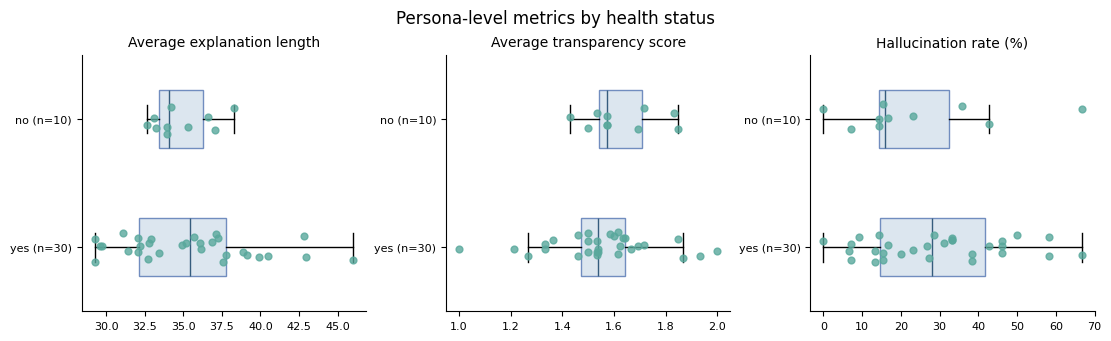

In [22]:
factor = "health_status"

metric_labels = {
    "avg_explanation_length": "Average explanation length",
    "avg_transparency_score": "Average transparency score",
    "hallucination_rate": "Hallucination rate (%)",
}

fig, axes = plt.subplots(1, 3, figsize=(11, 3.3), layout="constrained")
rng = np.random.default_rng(42)

for ax, metric in zip(axes, metrics):
    valid = persona_analysis_df[[factor, metric]].dropna()
    groups = list(valid.groupby(factor, observed=True)[metric])

    if not groups:
        ax.set_title(metric_labels[metric], fontsize=10)
        ax.text(0.5, 0.5, "No valid data", ha="center", transform=ax.transAxes)
        continue

    scale = 100 if metric == "hallucination_rate" else 1
    values = [series.to_numpy() * scale for _, series in groups]

    ax.boxplot(
        values,
        vert=False,
        widths=0.45,
        showfliers=False,
        patch_artist=True,
        boxprops={"facecolor": "#DCE6EF", "edgecolor": "#718DBF"},
        medianprops={"color": "#355C7D"},
    )

    for position, points in enumerate(values, start=1):
        jitter = rng.uniform(-0.12, 0.12, len(points))
        ax.scatter(
            points,
            position + jitter,
            s=24,
            color="#59A89C",
            alpha=0.8,
            zorder=3,
        )

    ax.set_yticks(
        range(1, len(groups) + 1),
        [f"{name} (n={len(series)})" for name, series in groups],
    )
    ax.invert_yaxis()
    ax.set_title(metric_labels[metric], fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(labelsize=8)

fig.suptitle(f"Persona-level metrics by {factor.replace('_', ' ')}", fontsize=12)
plt.show()

### b. T-tests for binary factors

In [23]:
from scipy import stats

# select factors with two observed categories
binary_factors = [
    factor for factor in factors
    if persona_analysis_df[factor].dropna().nunique() == 2
]

print("Binary factors:", binary_factors)

test_rows = []

for factor in binary_factors:
    labels = sorted(persona_analysis_df[factor].dropna().unique())

    # use yes minus no for binary profile indicators
    if set(labels) == {"yes", "no"}:
        labels = ["yes", "no"]

    for metric in metrics:
        a, b = [
            persona_analysis_df.loc[
                persona_analysis_df[factor].eq(label), metric
            ].dropna().to_numpy(dtype=float)
            for label in labels
        ]

        row = {
            "factor": factor,
            "metric": metric,
            "test": "welch t-test",
            "group_1": labels[0],
            "group_2": labels[1],
            "n_1": len(a),
            "n_2": len(b),
            "mean_1": a.mean() if len(a) else np.nan,
            "mean_2": b.mean() if len(b) else np.nan,
            "mean_difference": np.nan,
            "t": np.nan,
            "p": np.nan,
            "hedges_g": np.nan,
            "note": "",
        }

        if len(a) and len(b):
            row["mean_difference"] = a.mean() - b.mean()

        if min(len(a), len(b)) < 2:
            row["note"] = "not tested: n < 2"
        elif a.var(ddof=1) == 0 or b.var(ddof=1) == 0:
            row["note"] = "not tested: zero within-group variance"
        else:
            test = stats.ttest_ind(a, b, equal_var=False)

            # pooled standard deviation for the descriptive effect size
            pooled_df = len(a) + len(b) - 2
            pooled_sd = np.sqrt(
                (
                    (len(a) - 1) * a.var(ddof=1)
                    + (len(b) - 1) * b.var(ddof=1)
                ) / pooled_df
            )
            correction = 1 - 3 / (4 * pooled_df - 1)

            row.update({
                "t": float(test.statistic),
                "p": float(test.pvalue),
                "hedges_g": correction * row["mean_difference"] / pooled_sd,
                "note": "small group: n < 5" if min(len(a), len(b)) < 5 else "",
            })

        test_rows.append(row)

ttest_results = pd.DataFrame(test_rows)
display(ttest_results.round(4))

Binary factors: ['health_status', 'dietary_restriction']


,factor,metric,test,group_1,group_2,n_1,n_2,mean_1,mean_2,mean_difference,t,p,hedges_g,note
0,health_status,avg_explanation_length,welch t-test,yes,no,30,10,35.4432,34.8334,0.6098,0.6116,0.5448,0.1527,
1,health_status,avg_transparency_score,welch t-test,yes,no,30,10,1.5550,1.6262,-0.0713,-1.2173,0.2356,-0.3568,
2,health_status,hallucination_rate,welch t-test,yes,no,30,10,0.2889,0.2361,0.0529,0.7549,0.4628,0.2865,
3,dietary_restriction,avg_explanation_length,welch t-test,yes,no,32,8,35.2351,35.5135,-0.2784,-0.1950,0.8486,-0.0696,
4,dietary_restriction,avg_transparency_score,welch t-test,yes,no,32,8,1.5517,1.6572,-0.1055,-1.1297,0.2881,-0.5345,
5,dietary_restriction,hallucination_rate,welch t-test,yes,no,32,8,0.2995,0.1805,0.1190,1.6605,0.1266,0.6638,


### c. One-way ANOVA for multi-group factors

In [24]:
# select factors with at least three observed categories
multi_factors = [
    factor for factor in factors
    if persona_analysis_df[factor].dropna().nunique() >= 3
]

print("Multi-group factors:", multi_factors)

anova_rows = []

for factor in multi_factors:
    labels = (
        persona_analysis_df.groupby(factor, observed=True, sort=True)
        .size().index.tolist()
    )

    for metric in metrics:
        groups = [
            persona_analysis_df.loc[
                persona_analysis_df[factor].eq(label), metric
            ].dropna().to_numpy(dtype=float)
            for label in labels
        ]
        sizes = [len(group) for group in groups]

        row = {
            "factor": factor,
            "metric": metric,
            "test": "one-way anova",
            "groups": labels,
            "sizes": sizes,
            "means": [
                group.mean() if len(group) else np.nan
                for group in groups
            ],
            "F": np.nan,
            "df_between": len(groups) - 1,
            "df_within": sum(sizes) - len(groups),
            "p": np.nan,
            "eta_squared": np.nan,
            "note": "",
        }

        if min(sizes) == 0:
            row["note"] = "not tested: a group has no valid metric"
        elif row["df_within"] <= 0:
            row["note"] = "not tested: no pooled residual degrees of freedom"
        elif np.ptp(np.concatenate(groups)) == 0:
            row["note"] = "not tested: all values are identical"
        else:
            test = stats.f_oneway(*groups)

            # descriptive share of variation between groups
            values = np.concatenate(groups)
            grand_mean = values.mean()

            ss_between = sum(
                len(group) * (group.mean() - grand_mean) ** 2
                for group in groups
            )
            ss_total = ((values - grand_mean) ** 2).sum()

            row.update({
                "F": float(test.statistic),
                "p": float(test.pvalue),
                "eta_squared": ss_between / ss_total,
                "note": "small group: n < 5" if min(sizes) < 5 else "",
            })

        anova_rows.append(row)

anova_results = pd.DataFrame(anova_rows)
display(anova_results.round(4))

Multi-group factors: ['dietary_goal', 'age_group', 'gender']


,factor,metric,test,groups,sizes,means,F,df_between,df_within,p,eta_squared,note
0,dietary_goal,avg_explanation_length,one-way anova,"[Energy Boost, Maintenance, Medical Management...","[6, 8, 14, 5, 7]","[34.591987179487184, 32.99574175824176, 35.738...",1.3382,4,35,0.2752,0.1327,
1,dietary_goal,avg_transparency_score,one-way anova,"[Energy Boost, Maintenance, Medical Management...","[6, 8, 14, 5, 7]","[1.6366452991452993, 1.555952380952381, 1.4897...",1.7906,4,35,0.1528,0.1699,
2,dietary_goal,hallucination_rate,one-way anova,"[Energy Boost, Maintenance, Medical Management...","[6, 8, 14, 5, 7]","[0.2762286324786325, 0.28484432234432233, 0.31...",0.4410,4,35,0.7781,0.0480,
3,age_group,avg_explanation_length,one-way anova,"[under 18, 18-39, 40-59, 60+]","[3, 21, 12, 4]","[34.77655677655678, 35.94508309151167, 35.7441...",2.1823,3,36,0.1070,0.1539,small group: n < 5
4,age_group,avg_transparency_score,one-way anova,"[under 18, 18-39, 40-59, 60+]","[3, 21, 12, 4]","[1.5, 1.6153065188779476, 1.5994047619047622, ...",3.1353,3,36,0.0373,0.2072,small group: n < 5
5,age_group,hallucination_rate,one-way anova,"[under 18, 18-39, 40-59, 60+]","[3, 21, 12, 4]","[0.3516483516483517, 0.2515054390054391, 0.321...",0.7214,3,36,0.5458,0.0567,small group: n < 5
6,gender,avg_explanation_length,one-way anova,"[Female, Male, Non-binary]","[20, 19, 1]","[35.37297244422244, 35.13451898978215, 36.6153...",0.0747,2,37,0.9281,0.0040,small group: n < 5
7,gender,avg_transparency_score,one-way anova,"[Female, Male, Non-binary]","[20, 19, 1]","[1.5734478021978024, 1.5576923076923077, 1.846...",1.0339,2,37,0.3657,0.0529,small group: n < 5
8,gender,hallucination_rate,one-way anova,"[Female, Male, Non-binary]","[20, 19, 1]","[0.267130994005994, 0.28715056872951616, 0.230...",0.0879,2,37,0.9160,0.0047,small group: n < 5


### d. Multiple-testing correction (Benjamini–Hochberg FDR)

In [25]:
%pip install -q statsmodels

In [26]:
from statsmodels.stats.multitest import multipletests

# combine binary and multi-group comparisons
test_results = pd.concat(
    [ttest_results, anova_results],
    ignore_index=True,
)

# retain all planned factor-metric comparisons
planned_tests = pd.MultiIndex.from_product(
    [factors, metrics],
    names=["factor", "metric"],
)

assert not test_results.duplicated(["factor", "metric"]).any()

test_results = (
    test_results
    .set_index(["factor", "metric"])
    .reindex(planned_tests)
    .reset_index()
)

test_results["note"] = test_results["note"].fillna(
    "not tested: fewer than two observed groups"
)

# skipped tests enter the correction as 1, then remain unreported
valid = test_results["p"].notna()

_, adjusted_p, _, _ = multipletests(
    test_results["p"].fillna(1).to_numpy(),
    alpha=0.05,
    method="fdr_bh",
)

test_results["p_fdr"] = adjusted_p
test_results.loc[~valid, "p_fdr"] = np.nan

test_results["reject_fdr"] = pd.Series(
    pd.NA, index=test_results.index, dtype="boolean"
)
test_results.loc[valid, "reject_fdr"] = (
    test_results.loc[valid, "p_fdr"] < 0.05
)

display(
    test_results[
        ["factor", "metric", "test", "p", "p_fdr", "reject_fdr", "note"]
    ].round(4)
)

,factor,metric,test,p,p_fdr,reject_fdr,note
0,dietary_goal,avg_explanation_length,one-way anova,0.2752,0.6174,False,
1,dietary_goal,avg_transparency_score,one-way anova,0.1528,0.5730,False,
2,dietary_goal,hallucination_rate,one-way anova,0.7781,0.9281,False,
3,health_status,avg_explanation_length,welch t-test,0.5448,0.7443,False,
4,health_status,avg_transparency_score,welch t-test,0.2356,0.6174,False,
5,health_status,hallucination_rate,welch t-test,0.4628,0.7443,False,
6,dietary_restriction,avg_explanation_length,welch t-test,0.8486,0.9281,False,
7,dietary_restriction,avg_transparency_score,welch t-test,0.2881,0.6174,False,
8,dietary_restriction,hallucination_rate,welch t-test,0.1266,0.5730,False,
9,age_group,avg_explanation_length,one-way anova,0.1070,0.5730,False,small group: n < 5


### e. Summarize group differences and effect sizes

In [27]:
binary_summary = test_results.loc[
    test_results["test"].eq("welch t-test"),
    [
        "factor", "metric",
        "group_1", "group_2", "n_1", "n_2",
        "mean_1", "mean_2", "mean_difference",
        "hedges_g", "p", "p_fdr", "note",
    ],
].copy()


rate_rows = binary_summary["metric"].eq("hallucination_rate")
binary_summary.loc[
    rate_rows, ["mean_1", "mean_2", "mean_difference"]
] *= 100

binary_summary["unit"] = binary_summary["metric"].map({
    "avg_explanation_length": "words",
    "avg_transparency_score": "score",
    "hallucination_rate": "%; difference in percentage points",
})

anova_summary = test_results.loc[
    test_results["test"].eq("one-way anova"),
    [
        "factor", "metric", "groups", "sizes",
        "F", "df_between", "df_within",
        "eta_squared", "p", "p_fdr", "note",
    ],
].copy()

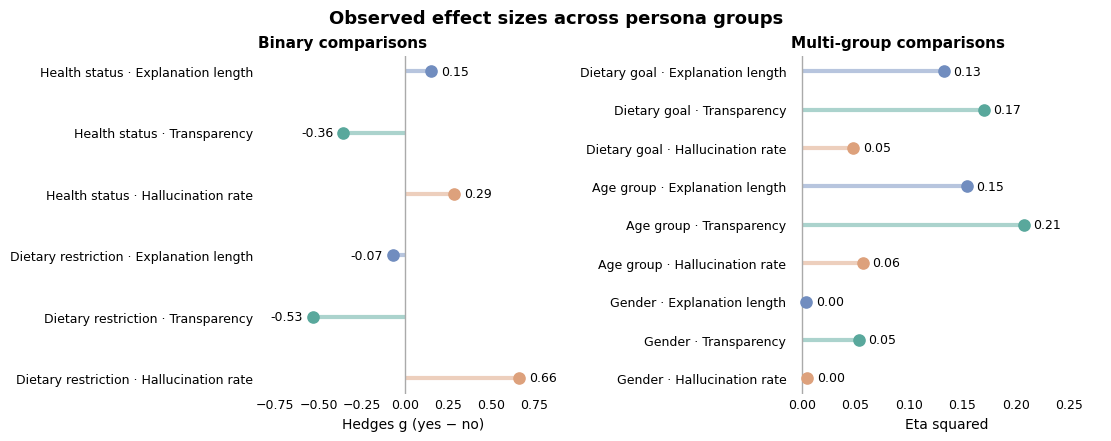

In [28]:
# display
metric_names = {
    "avg_explanation_length": "Explanation length",
    "avg_transparency_score": "Transparency",
    "hallucination_rate": "Hallucination rate",
}

metric_colors = {
    "avg_explanation_length": "#718DBF",
    "avg_transparency_score": "#59A89C",
    "hallucination_rate": "#DDA17C",
}

panels = [
    ("welch t-test", "hedges_g", "Binary comparisons", "Hedges g (yes − no)"),
    ("one-way anova", "eta_squared", "Multi-group comparisons", "Eta squared"),
]

fig, axes = plt.subplots(
    1, 2, figsize=(11, 4.3), layout="constrained"
)

for ax, (test, effect, title, xlabel) in zip(axes, panels):
    rows = test_results.loc[
        test_results["test"].eq(test)
        & test_results[effect].notna()
    ].copy()

    labels = []

    for y, row in enumerate(rows.itertuples(index=False)):
        value = getattr(row, effect)
        color = metric_colors[row.metric]

        ax.hlines(y, 0, value, color=color, linewidth=3, alpha=0.5)
        ax.scatter(value, y, color=color, s=65, zorder=3)

        ax.annotate(
            f"{value:.2f}",
            (value, y),
            xytext=(7 if value >= 0 else -7, 0),
            textcoords="offset points",
            ha="left" if value >= 0 else "right",
            va="center",
            fontsize=9,
        )

        factor_name = row.factor.replace("_", " ").capitalize()
        labels.append(f"{factor_name} · {metric_names[row.metric]}")

    ax.set_yticks(range(len(labels)), labels)
    ax.invert_yaxis()
    ax.axvline(0, color="#AAAAAA", linewidth=1)
    ax.set_title(title, loc="left", fontsize=11, fontweight="bold")
    ax.set_xlabel(xlabel, fontsize=10)
    ax.tick_params(axis="both", length=0, labelsize=9)

    for spine in ax.spines.values():
        spine.set_visible(False)

axes[0].set_xlim(-0.85, 0.95)
axes[1].set_xlim(-0.01, 0.28)

fig.suptitle(
    "Observed effect sizes across persona groups",
    fontsize=13,
    fontweight="bold",
)

plt.show()

## 4.4 Save Analysis Results